# Résultats du balayage de alpha : impact de la collaboration

Ce notebook lit un dossier produit par `run_alpha_sweep.py` (`results/<date>_alpha_sweep/`) et affiche :

1. la configuration ;
2. le tableau de synthèse par alpha (médiane [quantile 5 % ; quantile 95 %] sur les graines) ;
3. l'accuracy en fonction de alpha (consensus, agent médian, meilleur agent) ;
4. le gain de la collaboration par rapport aux agents indépendants (alpha = 0) ;
5. la diversité des agents (désaccord) en fonction de alpha ;
6. les courbes d'apprentissage pour chaque alpha ;
7. la calibration (NLL, ECE) en fonction de alpha.

Régler `RUN_DIR` ci-dessous (par défaut : le balayage le plus récent) puis *Run All*.

In [1]:
import glob
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import Markdown, display

# --- À régler -------------------------------------------------------------
RESULTS_ROOT = "results"   # dossier contenant les runs
RUN_DIR = None             # None = balayage le plus récent ; sinon "results/20261019-..._alpha_sweep"
# ---------------------------------------------------------------------------

def is_sweep(d):
    try:
        with open(os.path.join(d, "results.json")) as f:
            return json.load(f).get("experiment") == "alpha_sweep"
    except (FileNotFoundError, json.JSONDecodeError):
        return False

if RUN_DIR is None:
    sweeps = sorted(d for d in glob.glob(os.path.join(RESULTS_ROOT, "*")) if is_sweep(d))
    if not sweeps:
        raise FileNotFoundError(f"Aucun balayage de alpha terminé dans {os.path.abspath(RESULTS_ROOT)}")
    RUN_DIR = sweeps[-1]

with open(os.path.join(RUN_DIR, "config.json")) as f:
    config = json.load(f)
with open(os.path.join(RUN_DIR, "results.json")) as f:
    results = json.load(f)

runs = results["runs"]
alphas = sorted({r["alpha"] for r in runs})
seeds = sorted({r["seed"] for r in runs})
by_alpha = {a: [r for r in runs if r["alpha"] == a] for a in alphas}
print(f"Run : {os.path.abspath(RUN_DIR)}")
print(f"alphas : {[f'{a:g}' for a in alphas]}  |  graines : {seeds}  |  runs terminés : {len(runs)}")

Run : c:\Users\jketchak\Documents\DALPHAcommunity\UNAMUR\EUREKA\btwg_ml\MultiAgentsAI\results\20261019-153521_alpha_sweep
alphas : ['0', '0.5', '1', '10', '50', '100']  |  graines : [0, 1, 2]  |  runs terminés : 15


In [2]:
# --- Style commun des figures ----------------------------------------------
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
CONS = "#2a78d6"     # consensus
AGENT = "#eb6834"    # agent médian
GRAY = "#a9a79f"     # meilleur agent / contexte
# Rampe ordinale (bleus) : un alpha plus grand = plus foncé
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b", "#082a52"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
})

FIG_DIR = os.path.join(RUN_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"))

Q_LO, Q_HI = 0.05, 0.95

def stats(values, axis=None):
    """Médiane, quantile 5 % et quantile 95 % (sur les graines)."""
    v = np.asarray(values, dtype=float)
    return np.median(v, axis=axis), np.quantile(v, Q_LO, axis=axis), np.quantile(v, Q_HI, axis=axis)

def per_alpha(key, transform=lambda r, k: r[k]):
    """Pour chaque alpha : (médiane, q05, q95) de la métrique sur les graines (None si absente)."""
    out = []
    for a in alphas:
        vals = [transform(r, key) for r in by_alpha[a]]
        vals = [v for v in vals if v is not None]
        out.append(stats(vals) if vals else (np.nan, np.nan, np.nan))
    return np.array(out).T   # (3, n_alphas)

# alpha sur un axe à positions régulières (0 ; 0,5 ; 1 ; 10 ; 50 ; 100 sont trop inégaux pour un axe linéaire)
X = np.arange(len(alphas))
XLABELS = [f"{a:g}" for a in alphas]
def alpha_axis(ax):
    ax.set_xticks(X, XLABELS)
    ax.set_xlabel("alpha  (0 = agents indépendants, vote majoritaire)")
    ax.grid(axis="x", visible=False)

K = config["num_agents"]
TITLE = f"{K} × {config['arch']} — {config['loss_type']}"

## 1. Configuration

In [3]:
rows = {
    "Jeu de données": config["dataset"],
    "Agents": f"{K} × {config['arch']}  ({config.get('agent_params', 0):,} param. chacun)",
    "Loss": f"{config['loss_type']} : L_k · (L_k + α · I_k)",
    "Alphas": ", ".join(XLABELS),
    "Stratégie de consensus": f"{config.get('strategy_alpha0', 'majority')} pour α = 0, {config['strategy']} sinon (τ = {config['temperature']})",
    "Optimiseur": f"{config['optimizer']}, lr = {config['lr']}" + (f", {config['optimizer_kwargs']}" if config.get("optimizer_kwargs") else ""),
    "Entraînement": f"{config['epochs']} epochs (warmup {config['warmup_epochs']}), batch {config['batch_size']}, weight decay {config['weight_decay']}, augmentation : {config['augment']}",
    "Validation / sous-ensemble": f"val_size = {config['val_size']}, train_subset = {config['train_subset']}",
    "Graines": ", ".join(map(str, seeds)),
    "Matériel": f"{config.get('device', '?')}, précision {config['precision']}",
    "Durée d'entraînement": f"{results['train_time_s'] / 60:.1f} min",
}
display(pd.DataFrame({"": list(rows.values())}, index=list(rows.keys()))
        .style.set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("font-weight", "600")]}]))

,
Jeu de données,cifar10
Agents,"3 × resnet20 (272,474 param. chacun)"
Loss,global_interaction : L_k · (L_k + α · I_k)
Alphas,"0, 0.5, 1, 10, 50, 100"
Stratégie de consensus,"majority pour α = 0, simplicial sinon (τ = 1.0)"
Optimiseur,"sgd, lr = 0.001"
Entraînement,"10 epochs (warmup 5), batch 128, weight decay 0.0005, augmentation : True"
Validation / sous-ensemble,"val_size = 10000, train_subset = None"
Graines,"0, 1, 2"
Matériel,"gpu, précision float32"


## 2. Tableau de synthèse

Médiane [quantile 5 % ; quantile 95 %] sur les graines. En gras : le meilleur alpha de chaque colonne. Avec peu de graines, les quantiles sont proches du minimum et du maximum.

In [4]:
med_agent = lambda key: (lambda r, k: float(np.median(r[key])))
COLUMNS = {
    "Consensus (%)": ("accuracy_consensus", None, 100, "max"),
    "Moyenne simple (%)": ("accuracy_mean_ensemble", None, 100, "max"),
    "Agent médian (%)": ("accuracy_agent_median", None, 100, "max"),
    "Meilleur agent (%)": ("accuracy_agent_best", None, 100, "max"),
    "Désaccord (%)": ("disagreement", None, 100, None),
    "NLL consensus": ("nll_consensus", None, 1, "min"),
    "ECE consensus": ("ece_consensus", None, 1, "min"),
    "NLL agent médian": ("nll_agents", med_agent("nll_agents"), 1, "min"),
}
table, medians = {}, {}
for col, (key, tf, scale, _) in COLUMNS.items():
    m, lo, hi = per_alpha(key, tf) if tf else per_alpha(key)
    m, lo, hi = m * scale, lo * scale, hi * scale
    digits = 2 if scale == 100 else 4
    table[col] = [f"{a:.{digits}f} [{b:.{digits}f} ; {c:.{digits}f}]" if not np.isnan(a) else "–"
                  for a, b, c in zip(m, lo, hi)]
    medians[col] = m
index = [f"{a:g} ({by_alpha[a][0]['strategy']})" for a in alphas]
table = pd.DataFrame(table, index=pd.Index(index, name="alpha"))
medians = pd.DataFrame(medians, index=index)

def highlight(col):
    rule = COLUMNS[col.name][3]
    if rule is None or medians[col.name].isna().all():
        return [""] * len(col)
    best = medians[col.name].idxmax() if rule == "max" else medians[col.name].idxmin()
    return ["font-weight: 700" if i == best else "" for i in col.index]

display(table.style.apply(highlight)
        .set_properties(**{"text-align": "right", "font-variant-numeric": "tabular-nums"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

,Consensus (%),Moyenne simple (%),Agent médian (%),Meilleur agent (%),Désaccord (%),NLL consensus,ECE consensus,NLL agent médian
alpha,,,,,,,,
0 (majority),60.96 [60.04 ; 61.68],62.15 [61.28 ; 62.46],58.81 [57.73 ; 59.15],58.90 [58.12 ; 59.39],31.45 [30.97 ; 32.27],–,–,1.2035 [1.2025 ; 1.2260]
0.5 (simplicial),66.76 [66.73 ; 66.91],66.79 [66.78 ; 67.11],63.51 [63.47 ; 63.62],63.66 [63.57 ; 64.73],27.78 [27.36 ; 28.62],1.0088 [1.0023 ; 1.0097],0.1544 [0.1540 ; 0.1550],1.0526 [1.0491 ; 1.0547]
1 (simplicial),70.15 [69.73 ; 70.28],70.23 [69.67 ; 70.26],66.88 [66.50 ; 67.08],67.57 [67.18 ; 67.62],25.43 [25.03 ; 25.93],0.9051 [0.9007 ; 0.9124],0.1373 [0.1364 ; 0.1419],0.9543 [0.9465 ; 0.9617]
10 (simplicial),82.40 [82.33 ; 82.47],82.42 [82.28 ; 82.56],80.12 [80.04 ; 80.21],80.36 [80.34 ; 80.38],15.63 [15.56 ; 15.69],0.5332 [0.5310 ; 0.5355],0.0720 [0.0708 ; 0.0732],0.5767 [0.5748 ; 0.5785]
50 (simplicial),85.67 [85.63 ; 85.72],85.65 [85.64 ; 85.66],83.62 [83.44 ; 83.81],84.06 [84.04 ; 84.07],12.70 [12.35 ; 13.04],0.4268 [0.4261 ; 0.4275],0.0451 [0.0433 ; 0.0468],0.4728 [0.4685 ; 0.4771]
100 (simplicial),86.36 [86.24 ; 86.48],86.39 [86.20 ; 86.59],84.53 [84.30 ; 84.76],84.67 [84.52 ; 84.83],12.00 [11.98 ; 12.03],0.4056 [0.4030 ; 0.4082],0.0398 [0.0386 ; 0.0411],0.4463 [0.4424 ; 0.4502]


## 3. Accuracy en fonction de alpha

Ligne : médiane sur les graines ; bande : quantiles 5 %–95 % ; points : chaque graine.

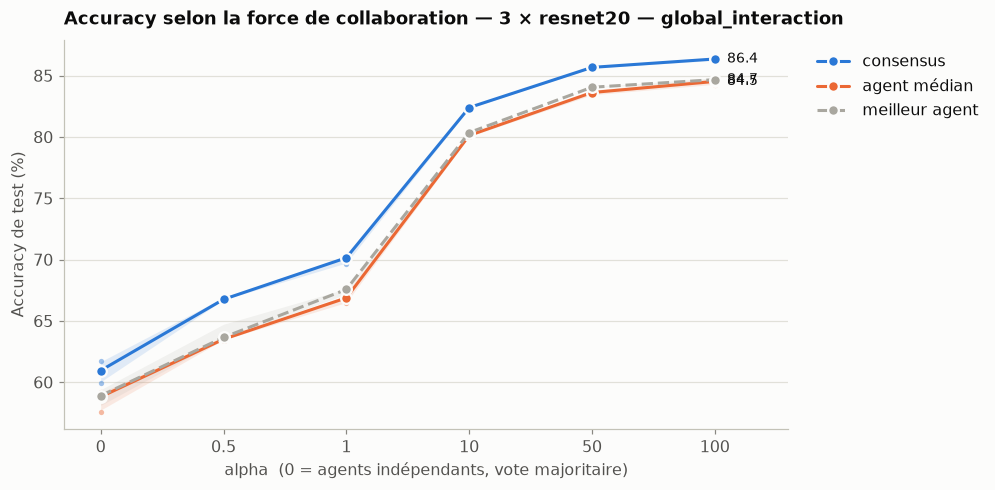

In [5]:
series = [
    ("consensus", "accuracy_consensus", CONS, "-"),
    ("agent médian", "accuracy_agent_median", AGENT, "-"),
    ("meilleur agent", "accuracy_agent_best", GRAY, "--"),
]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for label, key, color, ls in series:
    m, lo, hi = per_alpha(key) * 100
    ax.fill_between(X, lo, hi, color=color, alpha=0.13, lw=0)
    ax.plot(X, m, color=color, ls=ls, marker="o", ms=7, mec=SURFACE, mew=1.5, label=label, zorder=3)
    if key != "accuracy_agent_best":
        for j, a in enumerate(alphas):
            vals = [r[key] * 100 for r in by_alpha[a]]
            ax.scatter(np.full(len(vals), X[j]), vals, s=12, color=color, alpha=0.45, lw=0, zorder=2)
    ax.annotate(f"{m[-1]:.1f}", (X[-1], m[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
alpha_axis(ax)
ax.set_xlim(-0.3, len(alphas) - 0.4)
ax.set_ylabel("Accuracy de test (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_title(f"Accuracy selon la force de collaboration — {TITLE}")
save(fig, "accuracy_vs_alpha"); plt.show()

## 4. Gain de la collaboration

À gauche : gain du consensus sur l'agent médian **dans le même run** (ce que le groupe apporte par rapport à un de ses membres). À droite : accuracy de l'agent médian par rapport à alpha = 0 (agents indépendants) **sur la même graine** — ce que la collaboration apporte à chaque agent.

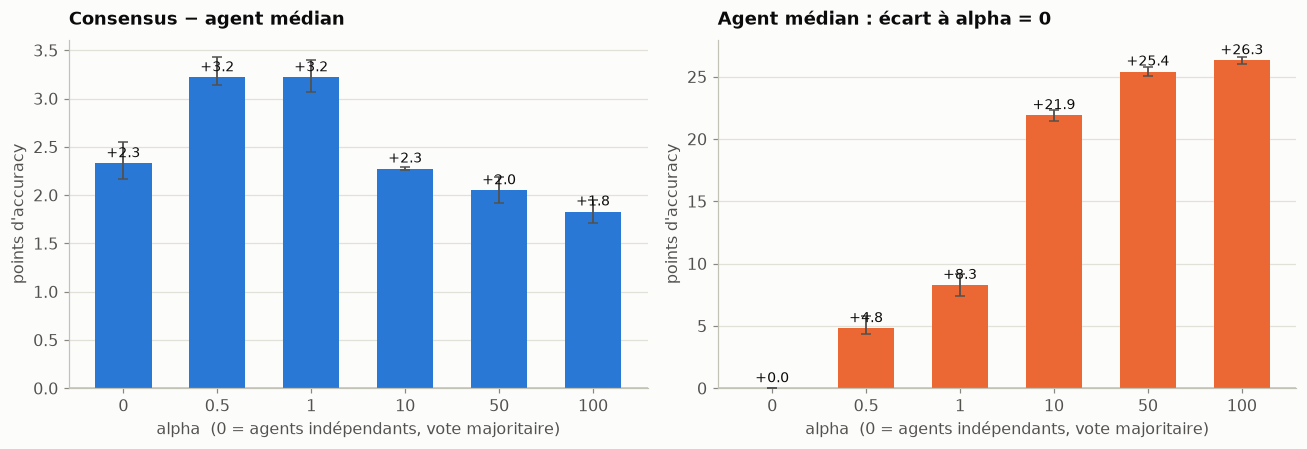

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Gain consensus - agent médian, par run
gain = [[(r["accuracy_consensus"] - r["accuracy_agent_median"]) * 100 for r in by_alpha[a]] for a in alphas]
m = np.array([stats(g) for g in gain]).T
ax = axes[0]
ax.axhline(0, color=AXIS, lw=1, zorder=1)
ax.bar(X, m[0], width=0.6, color=CONS, zorder=2)
ax.errorbar(X, m[0], yerr=[m[0] - m[1], m[2] - m[0]], fmt="none", ecolor=INK2, lw=1.2, capsize=3, zorder=3)
for x, v in zip(X, m[0]):
    ax.annotate(f"{v:+.1f}", (x, v), xytext=(0, 4 if v >= 0 else -12), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
alpha_axis(ax)
ax.set_ylabel("points d'accuracy")
ax.set_title("Consensus − agent médian")

# Agent médian vs alpha = 0, même graine
ax = axes[1]
if 0.0 in by_alpha:
    base = {r["seed"]: r["accuracy_agent_median"] for r in by_alpha[0.0]}
    delta = [[(r["accuracy_agent_median"] - base[r["seed"]]) * 100 for r in by_alpha[a] if r["seed"] in base]
             for a in alphas]
    m = np.array([stats(d) if d else (np.nan,) * 3 for d in delta]).T
    ax.axhline(0, color=AXIS, lw=1, zorder=1)
    colors = [GRAY if a == 0 else AGENT for a in alphas]
    ax.bar(X, m[0], width=0.6, color=colors, zorder=2)
    ax.errorbar(X, m[0], yerr=[m[0] - m[1], m[2] - m[0]], fmt="none", ecolor=INK2, lw=1.2, capsize=3, zorder=3)
    for x, v in zip(X, m[0]):
        if not np.isnan(v):
            ax.annotate(f"{v:+.1f}", (x, v), xytext=(0, 4 if v >= 0 else -12), textcoords="offset points",
                        ha="center", fontsize=9, color=INK)
    ax.set_title("Agent médian : écart à alpha = 0")
else:
    ax.text(0.5, 0.5, "alpha = 0 absent du balayage", ha="center", va="center", transform=ax.transAxes, color=MUTED)
    ax.set_title("Agent médian : écart à alpha = 0")
alpha_axis(ax)
ax.set_ylabel("points d'accuracy")
fig.tight_layout()
save(fig, "gain_collaboration"); plt.show()

## 5. Diversité des agents

Pourcentage moyen d'exemples de test sur lesquels deux agents prédisent une classe différente. Une collaboration forte rapproche les agents ; s'ils deviennent identiques, le consensus n'apporte plus rien.

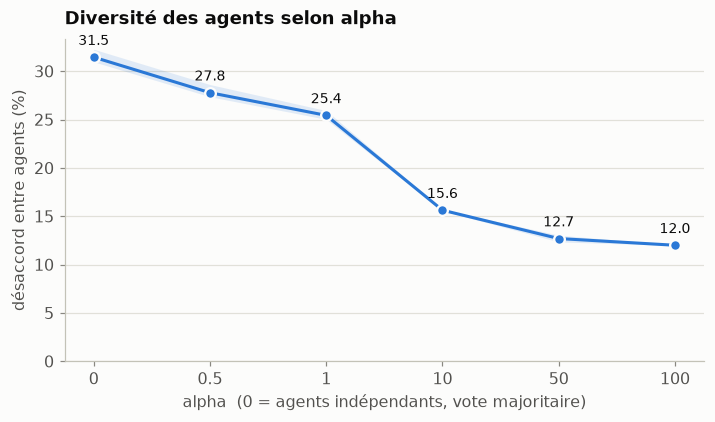

In [7]:
m, lo, hi = per_alpha("disagreement") * 100
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.fill_between(X, lo, hi, color=CONS, alpha=0.13, lw=0)
ax.plot(X, m, color=CONS, marker="o", ms=7, mec=SURFACE, mew=1.5, zorder=3)
for x, v in zip(X, m):
    ax.annotate(f"{v:.1f}", (x, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=INK)
alpha_axis(ax)
ax.set_ylim(bottom=0)
ax.set_ylabel("désaccord entre agents (%)")
ax.set_title("Diversité des agents selon alpha")
save(fig, "diversite_vs_alpha"); plt.show()

## 6. Courbes d'apprentissage

Accuracy du consensus (médiane sur les graines) pour chaque alpha ; plus le bleu est foncé, plus alpha est grand.

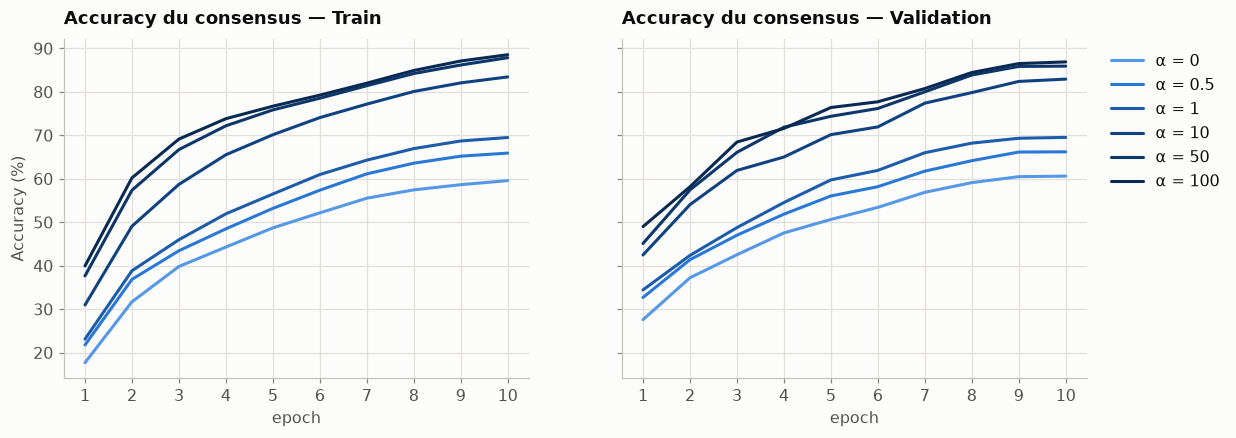

In [8]:
keys = [("accuracy", "Train"), ("val_accuracy", "Validation")]
keys = [k for k in keys if all(k[0] in r["history"] for r in runs)]
fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 4), sharey=True, squeeze=False)
ramp = RAMP[-len(alphas):] if len(alphas) <= len(RAMP) else plt.cm.Blues(np.linspace(0.35, 1, len(alphas)))
for ax, (key, title) in zip(axes[0], keys):
    for a, color in zip(alphas, ramp):
        curves = np.array([r["history"][key] for r in by_alpha[a]]) * 100
        x = np.arange(1, curves.shape[1] + 1)
        ax.plot(x, np.median(curves, 0), color=color, label=f"α = {a:g}")
    ax.set_title(f"Accuracy du consensus — {title}")
    ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0][0].set_ylabel("Accuracy (%)")
axes[0][-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
save(fig, "courbes_vs_alpha"); plt.show()

## 7. Calibration

NLL et ECE : plus bas = mieux. Pour alpha = 0 (vote majoritaire), le consensus ne donne pas de probabilités : seule la valeur de l'agent médian est affichée.

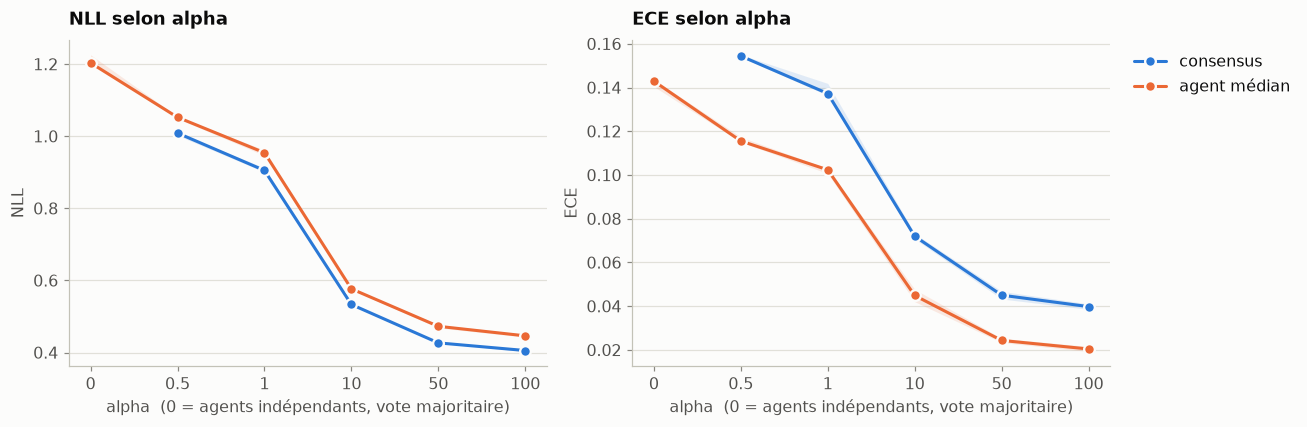

Figures enregistrées dans c:\Users\jketchak\Documents\DALPHAcommunity\UNAMUR\EUREKA\btwg_ml\MultiAgentsAI\results\20261019-153521_alpha_sweep\figures


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (metric, label) in zip(axes, [("nll", "NLL"), ("ece", "ECE")]):
    for name, key, tf, color in [
        ("consensus", f"{metric}_consensus", None, CONS),
        ("agent médian", f"{metric}_agents", lambda r, k: float(np.median(r[k])), AGENT),
    ]:
        m, lo, hi = per_alpha(key, tf) if tf else per_alpha(key)
        ok = ~np.isnan(m)
        ax.fill_between(X[ok], lo[ok], hi[ok], color=color, alpha=0.13, lw=0)
        ax.plot(X[ok], m[ok], color=color, marker="o", ms=7, mec=SURFACE, mew=1.5, label=name, zorder=3)
    alpha_axis(ax)
    ax.set_title(f"{label} selon alpha")
    ax.set_ylabel(label)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout()
save(fig, "calibration_vs_alpha"); plt.show()
print(f"Figures enregistrées dans {os.path.abspath(FIG_DIR)}")